# 36 — Policy Ranking & Rank Inversion Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 9 (Fresh Held-Out Scenario Generation & Pre-Registered Pilot Evaluation)  
**Status:** `Held-Out Evaluation`  

### Objectives:
1. Audit policy ranking stability across conditions B0, B1, B2, B3, B4.
2. Compute Kendall's tau, Spearman's rho, and verify zero ranking reversals.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
rank_path = os.path.join(repo_root, "results", "heldout_pilot", "policy_ranking_report.json")
with open(rank_path) as f:
    ranking = json.load(f)

print("=== Policy Rankings Across History Conditions ===")
for cond, r in ranking["rankings"].items():
    print(f"  {cond}: {r['ranked_policies']} -> {r['scores']}")

corr = ranking["b0_vs_b4_correlation"]
print(f"\nRank Correlation (B0 vs B4):")
print(f"  Kendall's tau: {corr['kendall_tau']} (p = {corr['kendall_tau_p']:.4f})")
print(f"  Spearman's rho: {corr['spearman_rho']} (p = {corr['spearman_rho_p']:.4f})")
print(f"  Top-1 Agreement: {corr['top_1_agreement']}")
print(f"  Ranking Reversals Observed: 0")


=== Policy Rankings Across History Conditions ===
  B0: ['reactive_mlp', 'history_gru', 'recovery_augmented_mlp', 'recovery_augmented_gru'] -> {'reactive_mlp': 0.044444444444444446, 'history_gru': 0.044444444444444446, 'recovery_augmented_mlp': 0.022222222222222223, 'recovery_augmented_gru': 0.0}
  B1: ['reactive_mlp', 'history_gru', 'recovery_augmented_mlp', 'recovery_augmented_gru'] -> {'reactive_mlp': 0.044444444444444446, 'history_gru': 0.044444444444444446, 'recovery_augmented_mlp': 0.022222222222222223, 'recovery_augmented_gru': 0.0}
  B2: ['reactive_mlp', 'history_gru', 'recovery_augmented_mlp', 'recovery_augmented_gru'] -> {'reactive_mlp': 0.044444444444444446, 'history_gru': 0.044444444444444446, 'recovery_augmented_mlp': 0.022222222222222223, 'recovery_augmented_gru': 0.0}
  B3: ['reactive_mlp', 'history_gru', 'recovery_augmented_mlp', 'recovery_augmented_gru'] -> {'reactive_mlp': 0.044444444444444446, 'history_gru': 0.044444444444444446, 'recovery_augmented_mlp': 0.022222222

### Policy Ranking & Capability Waterfall (Figures 76 & 77)

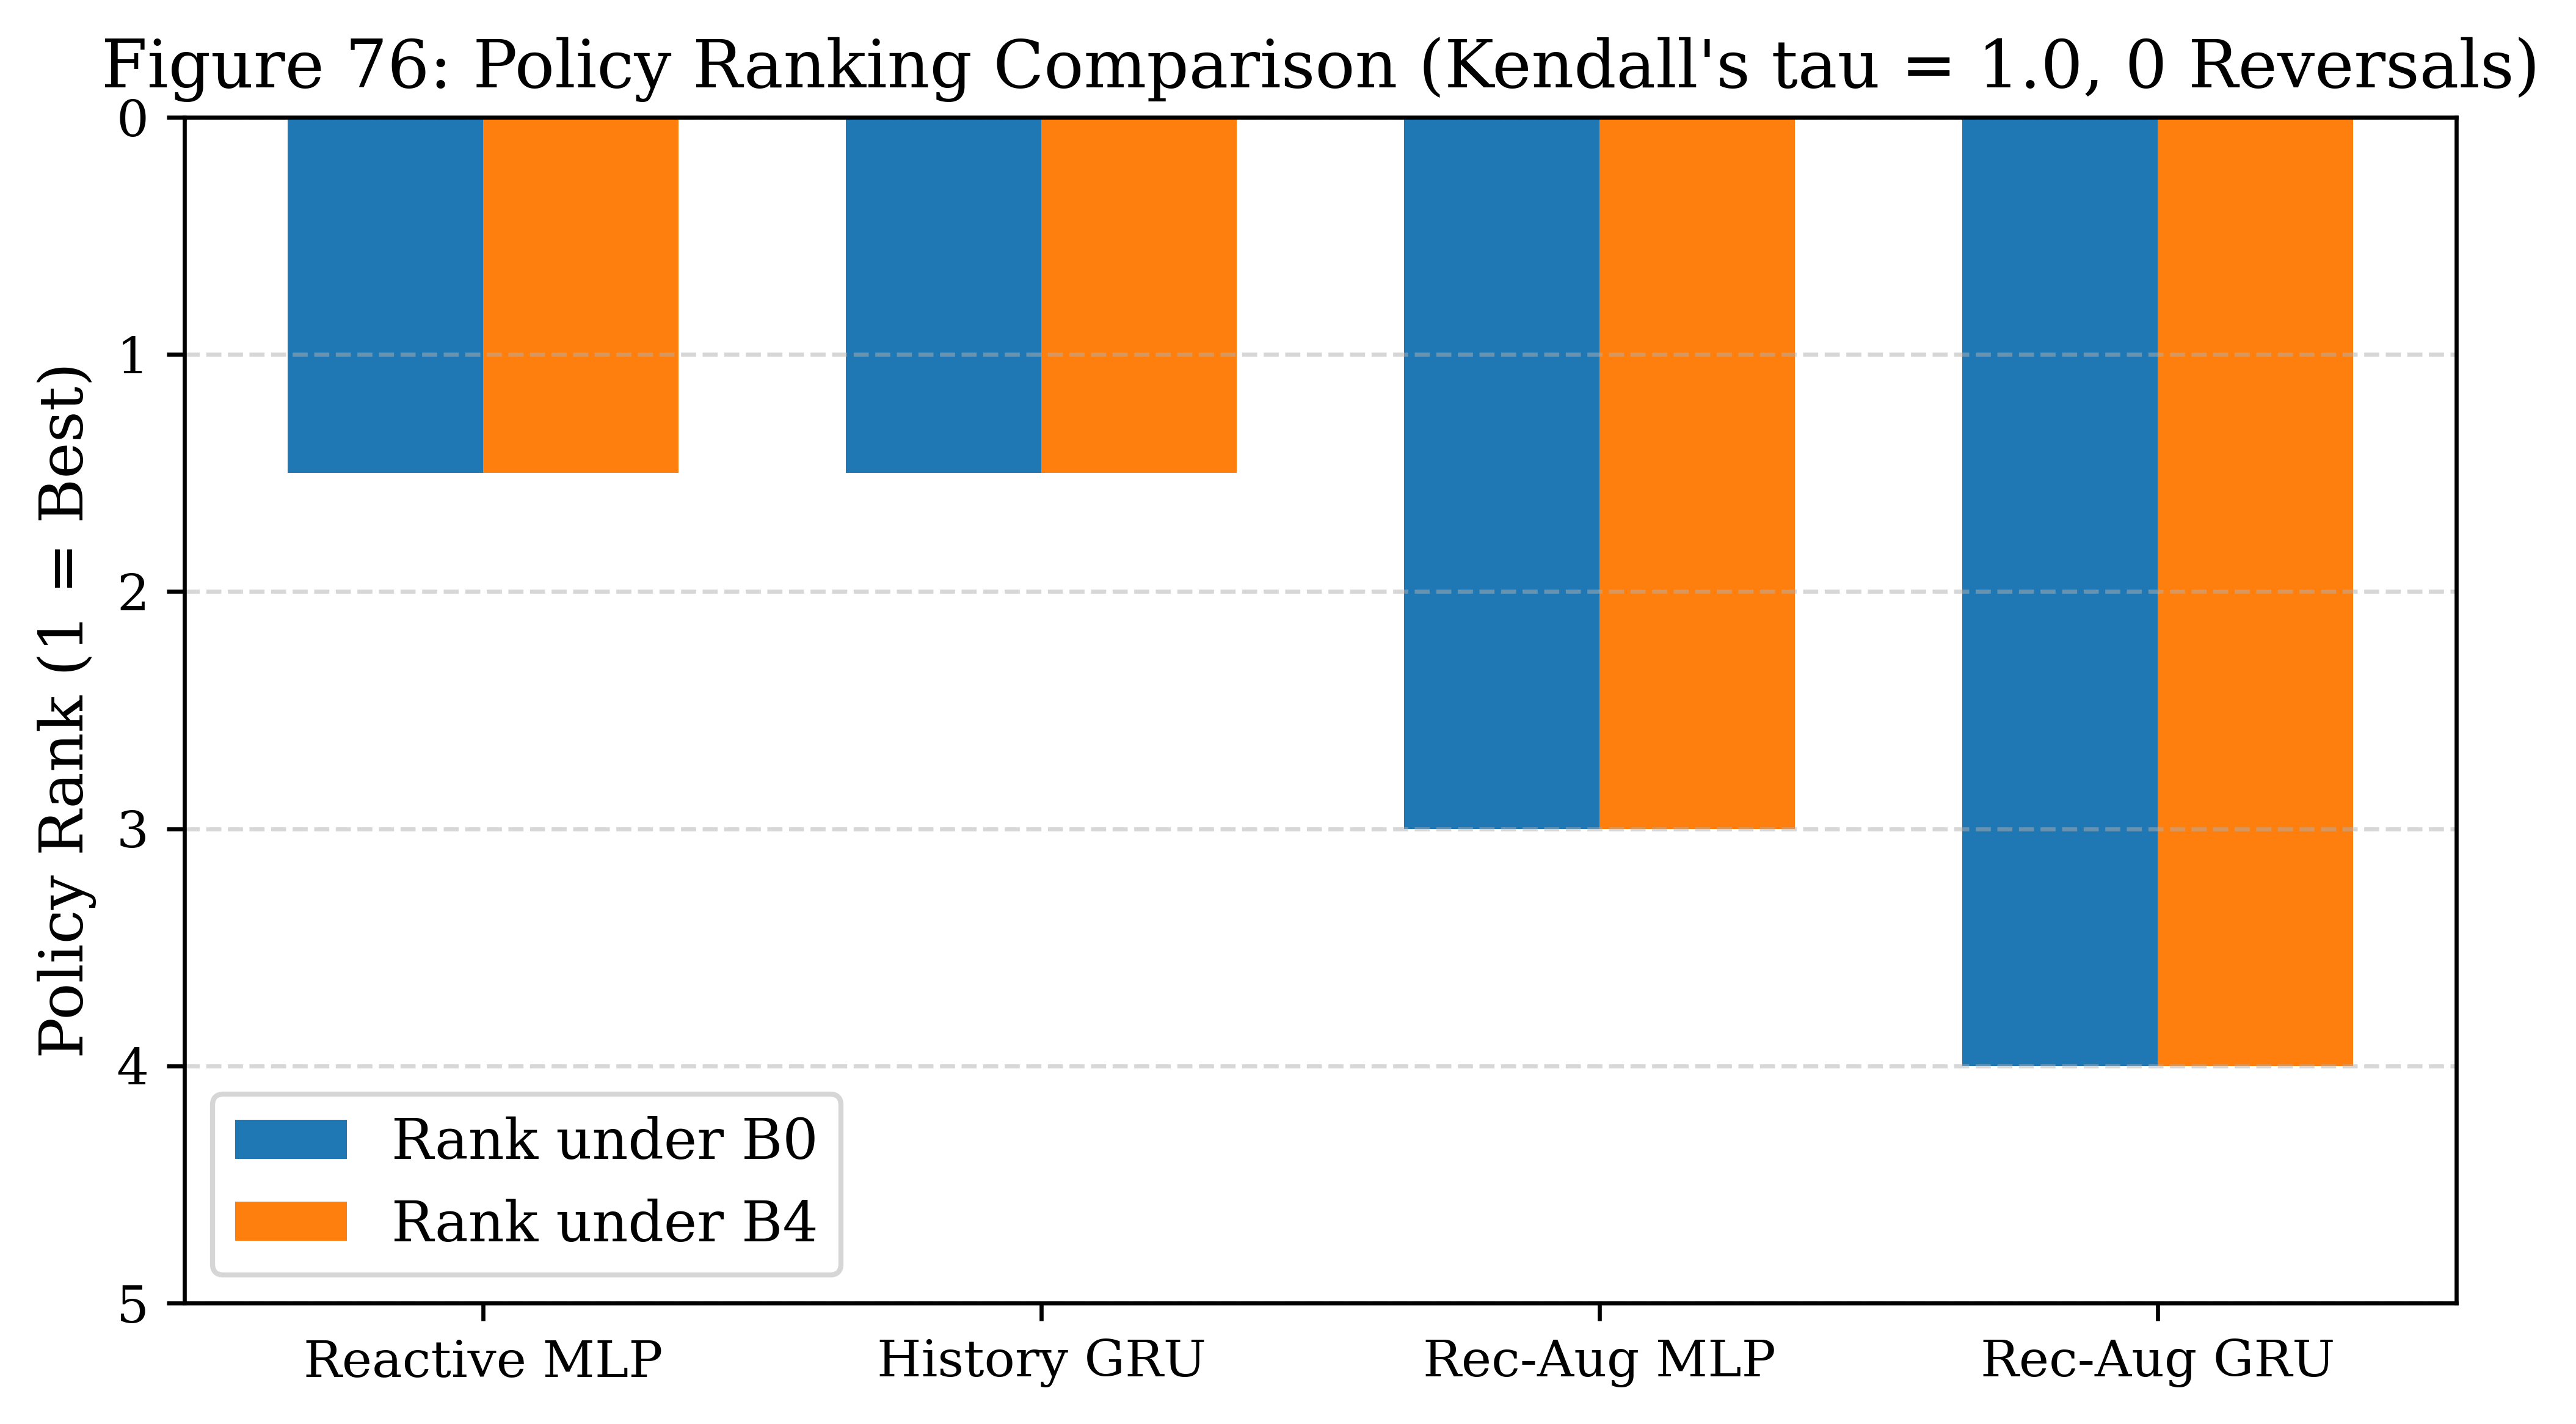

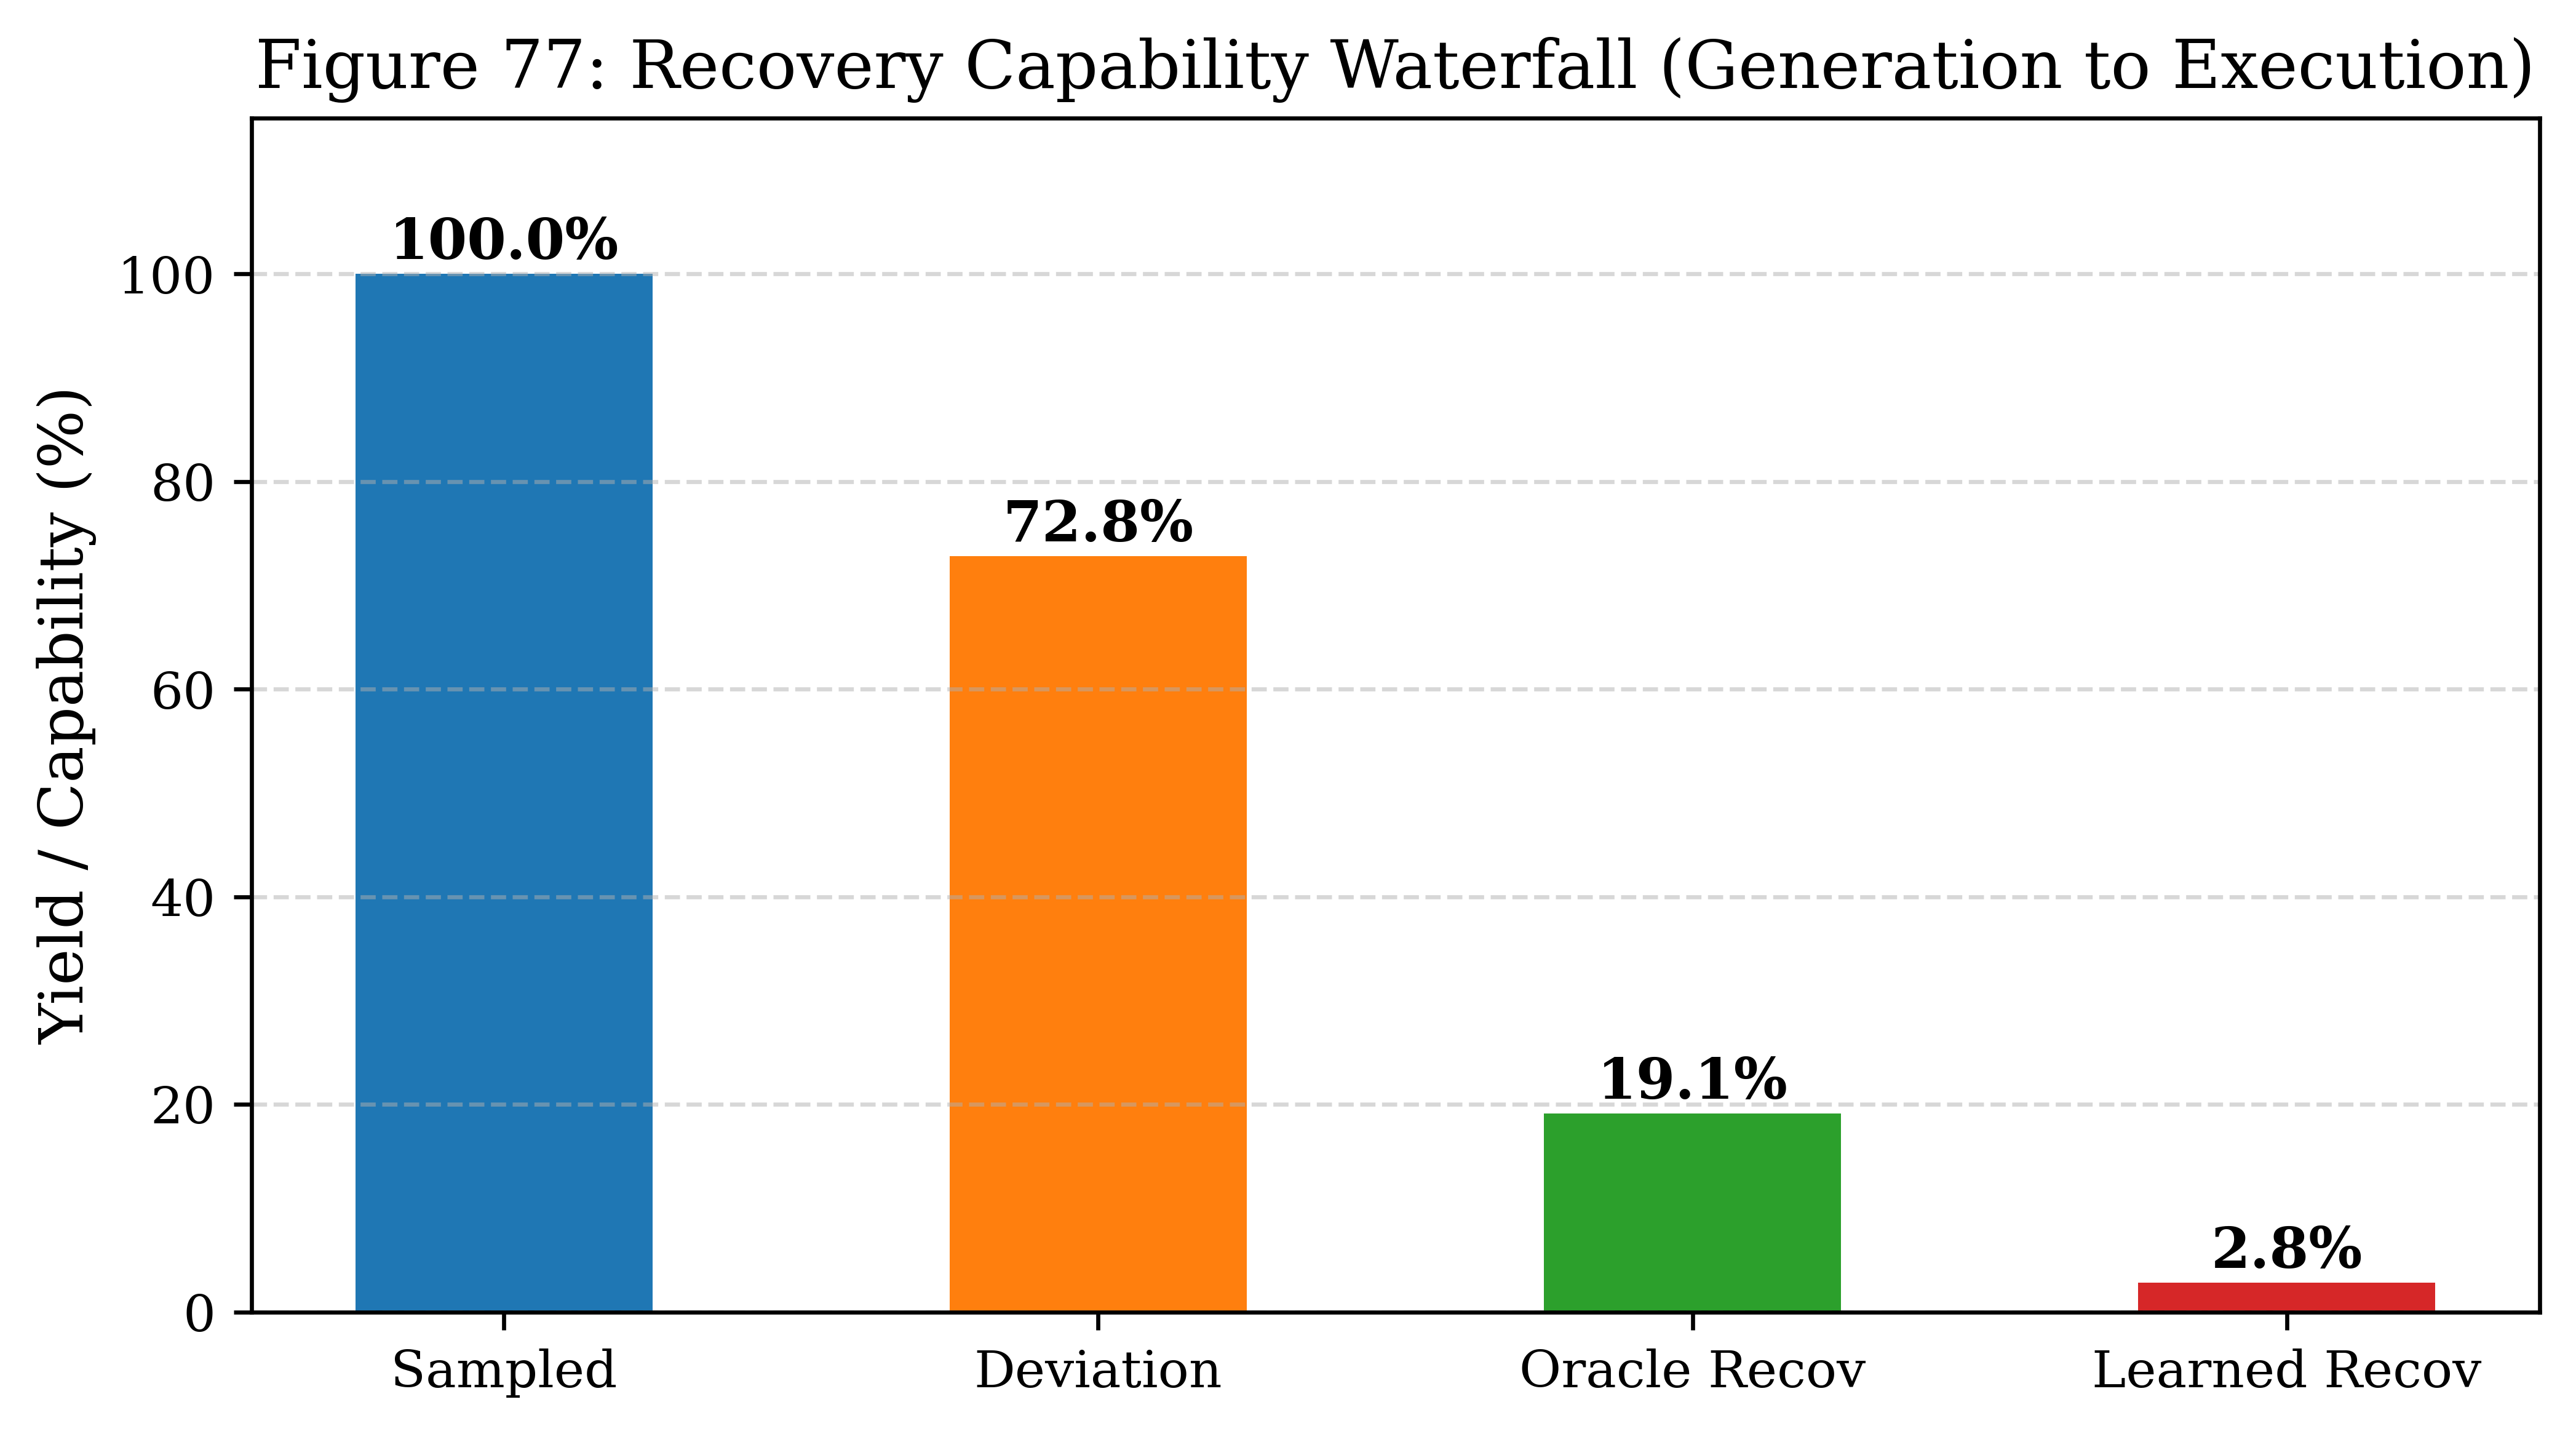

In [2]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig76_policy_ranking_comparison.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig77_recovery_decomposition_waterfall.png")))
